# Can a global flood model set a flood trigger where there is no gauge?

**KAI-Hydro · parametric flood triggers · Guadalquivir, Spain**

**Question.** A parametric flood policy pays when a river index crosses an agreed trigger. Where a river has no gauge, the index has to come from a global flood model. How often would a trigger set from the model have paid in the years the river actually flooded, and how often in years it did not?

**Data.**
* **Gauges:** daily mean river flow at the 14 gauges of the Guadalquivir basin with a catchment of at least 500 km² and at least 25 years of record in water years 1985–2022, from the *Anuario de Aforos 2021-2022* of CEDEX (Spain's Ministry for the Ecological Transition).
* **Global model:** daily river discharge from the GloFAS reanalysis (Copernicus Emergency Management Service; LISFLOOD, consolidated, version 4.0, served by the Open-Meteo flood API under CC BY 4.0).

This repository holds only what the notebook needs: each year's largest daily flow at each gauge and at its GloFAS river cell (`data/annual_maxima.csv`) and the gauge list (`data/gauges.csv`). The daily CEDEX files are not copied here; `rebuild_data.py` fetches them from CEDEX, checks their SHA-256 and rebuilds both files.

**Method.** Annual maxima by water year (October–September). Generalised extreme value (GEV) and log-Pearson type III (LP3) fitted by L-moments (Hosking and Wallis, 1997), the better fit chosen by probability-plot correlation, with a 90 % bootstrap band on each return level. A year counts as a flood year when the gauge passed its own 1-in-T level; a trigger set from the model pays when the model passes either its own 1-in-T level (a **return-period** trigger) or the gauge's level in m³/s (a **fixed-flow** trigger).

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import flood_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#dfe8e8", "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.facecolor": "white"})
GAUGE, MODEL, OK, AMBER, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"   # KAI chart palette
PERIODS = [2, 5, 10, 25, 50]
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)

gauges = pd.read_csv("data/gauges.csv").set_index("gauge_id")
am = pd.read_csv("data/annual_maxima.csv")
engine = json.loads(pathlib.Path("results/kai_engine_results.json").read_text())
print(len(gauges), "gauges ·", len(am), "gauge-years with both a measured and a modelled annual flood")
gauges[["name", "catchment_km2", "record_years_1985_2022", "km_gauge_to_cell", "glofas_mean_flow_ratio"]]

14 gauges · 286 gauge-years with both a measured and a modelled annual flood


,name,catchment_km2,record_years_1985_2022,km_gauge_to_cell,glofas_mean_flow_ratio
gauge_id,,,,,
5004,Mengibar,16166.0,28.0,8.0,0.158
5045,Loja,4210.0,31.2,11.1,0.388
5080,Puente Tocon,2944.0,26.5,6.5,0.481
5140,Villanueva De Las Torres,1685.0,31.0,10.4,0.900
5081,Castro Del Rio,1665.0,29.1,7.3,0.217
5057,Guadaira Encauzamiento,1318.0,25.9,6.6,0.559
5025,Llano De Vela,1240.0,27.4,8.6,0.150
5029,Mengibar Guadalbullon,1111.0,27.3,4.9,0.925
5077,Central De Cala,1010.0,33.3,11.6,0.419


## Where the gauges are

Each gauge is matched to the GloFAS river cell, within 0.1° (about 10 km), whose mean flow is closest to the gauge's. That uses the gauge, so it is the model's **best case**: at an ungauged site the cell has to be found from the catchment area alone. The interactive map on the [case page](https://kai-water.charkaks0.workers.dev/case-guadalquivir) shows the gauges and their cells over the river network, and lets you pick any point.

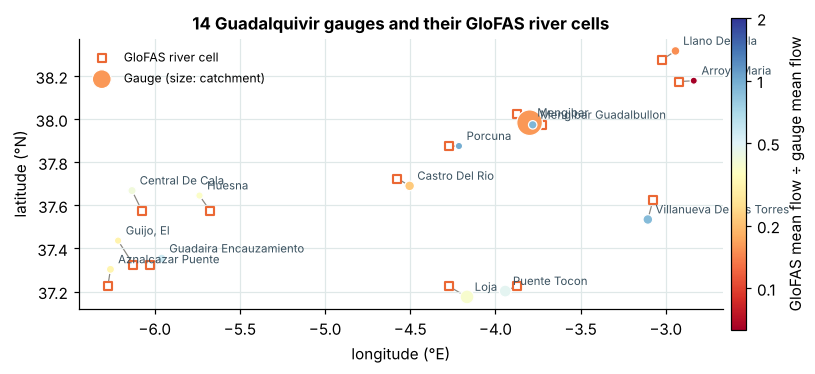

GloFAS mean flow is within a factor of 2 of the gauge at 4 of 14 gauges; median ratio 0.38


In [2]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ratio = gauges.glofas_mean_flow_ratio
for gid, g in gauges.iterrows():
    ax.plot([g.lon, g.glofas_cell_lon], [g.lat, g.glofas_cell_lat], color=GREY, lw=0.8, zorder=1)
ax.scatter(gauges.glofas_cell_lon, gauges.glofas_cell_lat, marker="s", s=28, facecolor="white", edgecolor=MODEL, lw=1.4, label="GloFAS river cell", zorder=2)
sc = ax.scatter(gauges.lon, gauges.lat, s=12 + gauges.catchment_km2 / 60, c=np.log10(ratio), cmap="RdYlBu", vmin=-1.2, vmax=0.3,
                edgecolor="white", lw=0.8, label="Gauge (size: catchment)", zorder=3)
for gid, g in gauges.iterrows():
    ax.annotate(g["name"], (g.lon, g.lat), xytext=(5, 4), textcoords="offset points", fontsize=7.5, color="#3b5260")
cb = fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.01); cb.set_ticks(np.log10([0.1, 0.2, 0.5, 1, 2])); cb.set_ticklabels(["0.1", "0.2", "0.5", "1", "2"])
cb.set_label("GloFAS mean flow ÷ gauge mean flow")
ax.set_aspect(1 / np.cos(np.radians(37.7))); ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)")
ax.set_title("14 Guadalquivir gauges and their GloFAS river cells"); ax.legend(loc="upper left", fontsize=8)
fig.savefig("figures/gq_map.png"); plt.show()
print(f"GloFAS mean flow is within a factor of 2 of the gauge at {int(((ratio >= 0.5) & (ratio <= 2)).sum())} of {len(ratio)} gauges; median ratio {ratio.median():.2f}")

## Flood-frequency curves at every gauge, measured and modelled

In [3]:
rows, curves = [], {}
for gid, g in gauges.iterrows():
    s = am[am.gauge_id == gid]
    for src, col in (("gauge", "gauge_max_m3s"), ("glofas", "glofas_max_m3s")):
        x = s[col].values
        best, fits = ft.fit_best(x)
        band = ft.bootstrap_band(x, best, PERIODS, n_boot=300, seed=0)
        curves[(gid, src)] = (best, fits[best], band)
        for t in PERIODS:
            rows.append({"gauge_id": gid, "name": g["name"], "source": src, "fit": best, "period": t,
                         "level_m3s": round(ft.level(fits[best], t), 2), "band_low": round(band[t][0], 2), "band_high": round(band[t][1], 2)})
levels = pd.DataFrame(rows); levels.to_csv("results/return_levels.csv", index=False)
ten = levels[levels.period == 10].pivot(index="name", columns="source", values="level_m3s")
ten["glofas ÷ gauge"] = (ten.glofas / ten.gauge).round(2)
print("median 10-year GloFAS ÷ gauge:", round(ten["glofas ÷ gauge"].median(), 3)); ten.sort_values("gauge", ascending=False)

median 10-year GloFAS ÷ gauge: 0.22


source,gauge,glofas,glofas ÷ gauge
name,,,
Guadaira Encauzamiento,403.62,45.36,0.11
Mengibar,354.57,70.17,0.20
Loja,135.03,62.17,0.46
Huesna,126.11,24.36,0.19
Aznalcazar Puente,114.18,26.46,0.23
"Guijo, El",113.31,11.23,0.10
Central De Cala,78.85,11.17,0.14
Puente Tocon,65.56,36.68,0.56
Castro Del Rio,55.52,12.67,0.23


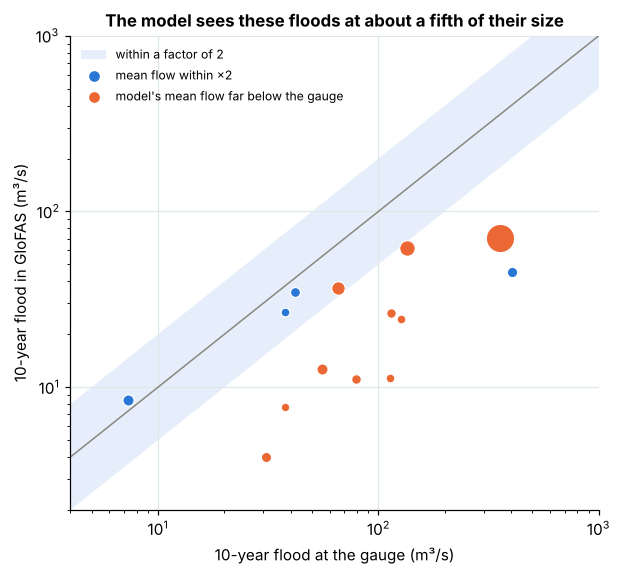

In [4]:
ok = (ratio >= 0.5) & (ratio <= 2)
fig, ax = plt.subplots(figsize=(6.2, 5.6))
d = np.array([2, 2000.0]); ax.fill_between(d, d / 2, d * 2, color=GAUGE, alpha=0.12, lw=0, label="within a factor of 2"); ax.plot(d, d, color=GREY, lw=1)
for gid, g in gauges.iterrows():
    gl, ml = ten.loc[g["name"], "gauge"], ten.loc[g["name"], "glofas"]
    ax.scatter(gl, ml, s=20 + g.catchment_km2 / 50, color=GAUGE if ok[gid] else MODEL, edgecolor="white", lw=0.8, zorder=3)
ax.scatter([], [], color=GAUGE, label="mean flow within ×2"); ax.scatter([], [], color=MODEL, label="model's mean flow far below the gauge")
ax.set(xscale="log", yscale="log", xlim=(4, 1000), ylim=(2, 1000), xlabel="10-year flood at the gauge (m³/s)", ylabel="10-year flood in GloFAS (m³/s)",
       title="The model sees these floods at about a fifth of their size"); ax.legend(loc="upper left", fontsize=8)
fig.savefig("figures/gq_levels.png"); plt.show()

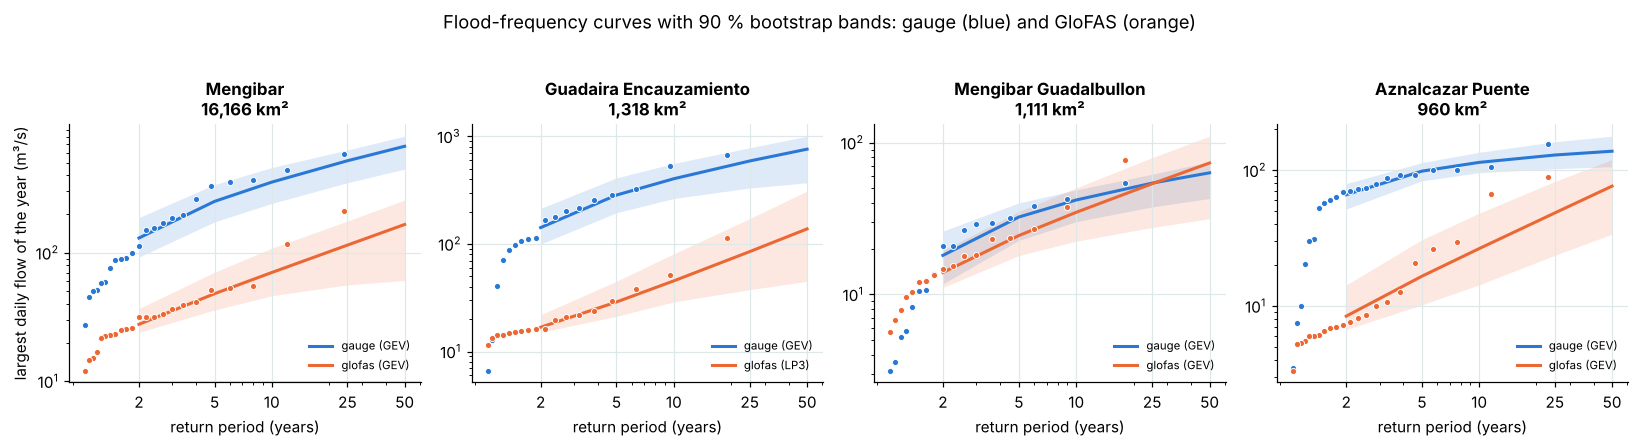

In [5]:
show = ["Mengibar", "Guadaira Encauzamiento", "Mengibar Guadalbullon", "Aznalcazar Puente"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=False)
P = np.array(PERIODS)
for ax, name in zip(axes, show):
    gid = gauges.index[gauges["name"] == name][0]; s = am[am.gauge_id == gid]
    for src, col, c in (("gauge", "gauge_max_m3s", GAUGE), ("glofas", "glofas_max_m3s", MODEL)):
        best, dist, band = curves[(gid, src)]
        x = np.sort(s[col].values)[::-1]; T = (len(x) + 1) / np.arange(1, len(x) + 1)
        ax.fill_between(P, [band[t][0] for t in P], [band[t][1] for t in P], color=c, alpha=0.15, lw=0)
        ax.plot(P, [ft.level(dist, t) for t in P], color=c, lw=2, label=f"{src} ({best})"); ax.plot(T, x, "o", ms=4, color=c, mec="white", mew=0.6)
    ax.set(xscale="log", yscale="log", title=f"{name}\n{gauges.loc[gid, 'catchment_km2']:,.0f} km²", xlabel="return period (years)")
    ax.set_xticks([2, 5, 10, 25, 50]); ax.set_xticklabels(["2", "5", "10", "25", "50"]); ax.legend(fontsize=7.5, loc="lower right")
axes[0].set_ylabel("largest daily flow of the year (m³/s)")
fig.suptitle("Flood-frequency curves with 90 % bootstrap bands: gauge (blue) and GloFAS (orange)", y=1.03); fig.tight_layout(); fig.savefig("figures/gq_frequency.png"); plt.show()

## Would the policy have paid?

For each gauge and each trigger level, a **flood year** is a year in which the gauge passed its own 1-in-T level. The trigger **pays** when the model passes its threshold. *Caught* = flood year and paid; *missed* = flood year, no payout; *false payout* = paid, no flood.

In [6]:
def score(gid, t, method):
    s = am[am.gauge_id == gid]
    lv_g = ft.level(curves[(gid, "gauge")][1], t); lv_m = ft.level(curves[(gid, "glofas")][1], t)
    line = lv_m if method == "return period" else lv_g
    floods = set(s.water_year[s.gauge_max_m3s >= lv_g]); paid = set(s.water_year[s.glofas_max_m3s >= line])
    return ft.trigger_score(floods, paid)

pooled = []
for t in [2, 5, 10, 25]:
    for method in ("return period", "fixed m³/s"):
        tot = pd.DataFrame([score(gid, t, method) for gid in gauges.index]).sum()
        pooled.append({"trigger": f"1 in {t}", "written as": method, **tot.to_dict(), "share caught": round(tot.caught / tot.flood_years, 2)})
pooled = pd.DataFrame(pooled); pooled.to_csv("results/trigger_scores.csv", index=False); pooled

,trigger,written as,caught,missed,false_payouts,flood_years,share caught
0,1 in 2,return period,93,50,50,143,0.65
1,1 in 2,fixed m³/s,33,110,20,143,0.23
2,1 in 5,return period,30,30,27,60,0.50
3,1 in 5,fixed m³/s,6,54,10,60,0.10
4,1 in 10,return period,13,23,19,36,0.36
5,1 in 10,fixed m³/s,2,34,4,36,0.06
6,1 in 25,return period,3,8,15,11,0.27
7,1 in 25,fixed m³/s,0,11,3,11,0.00


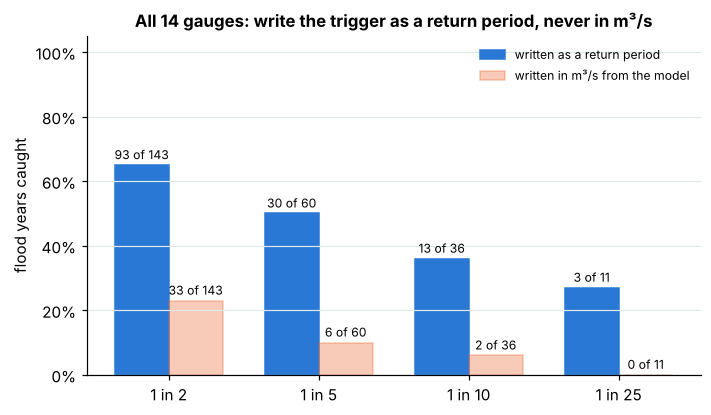

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4))
w = 0.36; xs = np.arange(4)
for k, (method, c, a) in enumerate((("return period", GAUGE, 1.0), ("fixed m³/s", MODEL, 0.35))):
    p = pooled[pooled["written as"] == method]
    b = ax.bar(xs + (k - 0.5) * w, p["share caught"], w, color=c, alpha=a, edgecolor=c, label=f"written as a {method}" if method == "return period" else "written in m³/s from the model")
    ax.bar_label(b, labels=[f"{r.caught} of {r.flood_years}" for r in p.itertuples()], fontsize=8, padding=2)
ax.grid(axis="x", visible=False); ax.set_xticks(xs, [f"1 in {t}" for t in (2, 5, 10, 25)]); ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(ylabel="flood years caught", title="All 14 gauges: write the trigger as a return period, never in m³/s"); ax.legend(fontsize=8, loc="upper right")
fig.savefig("figures/gq_triggers.png"); plt.show()

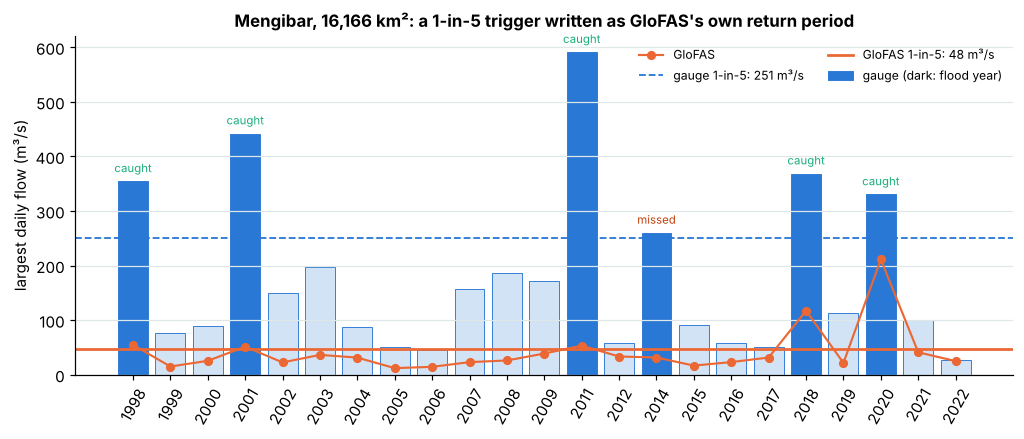

{'caught': 5, 'missed': 1, 'false_payouts': 0, 'flood_years': 6} | fixed m³/s: {'caught': 0, 'missed': 6, 'false_payouts': 0, 'flood_years': 6}


In [8]:
name = "Mengibar"; gid = gauges.index[gauges["name"] == name][0]; s = am[am.gauge_id == gid]; t = 5
lv_g = ft.level(curves[(gid, "gauge")][1], t); lv_m = ft.level(curves[(gid, "glofas")][1], t)
fig, ax = plt.subplots(figsize=(11, 4))
flood = s.gauge_max_m3s >= lv_g
ax.bar(s.water_year.astype(str), s.gauge_max_m3s, color=np.where(flood, GAUGE, "#d3e3f6"), edgecolor=GAUGE, lw=0.6, label="gauge (dark: flood year)")
ax.plot(s.water_year.astype(str), s.glofas_max_m3s, "o-", color=MODEL, ms=5, lw=1.4, label="GloFAS")
ax.axhline(lv_g, color=GAUGE, ls="--", lw=1.2, label=f"gauge 1-in-{t}: {lv_g:.0f} m³/s"); ax.axhline(lv_m, color=MODEL, lw=1.8, label=f"GloFAS 1-in-{t}: {lv_m:.0f} m³/s")
for i, (y, o, m) in enumerate(zip(s.water_year, s.gauge_max_m3s, s.glofas_max_m3s)):
    if o >= lv_g or m >= lv_m:
        kind = "caught" if (o >= lv_g and m >= lv_m) else "missed" if o >= lv_g else "false payout"
        ax.annotate(kind, (i, max(o, m)), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=7.5, color=OK if kind == "caught" else "#c2410c")
ax.set(ylabel="largest daily flow (m³/s)", title=f"{name}, {gauges.loc[gid, 'catchment_km2']:,.0f} km²: a 1-in-{t} trigger written as GloFAS's own return period")
ax.tick_params(axis="x", rotation=60); ax.grid(axis="x", visible=False); ax.legend(fontsize=8, ncol=2, loc="upper right"); fig.savefig("figures/gq_mengibar_years.png"); plt.show()
print(score(gid, t, "return period"), "| fixed m³/s:", score(gid, t, "fixed m³/s"))

## Basis risk: does the model get the big years right?

A return-period trigger cancels the model's bias in size, but not its errors in timing. The rank correlation of each gauge's annual floods with the model's measures that: at 1 the biggest years line up exactly.

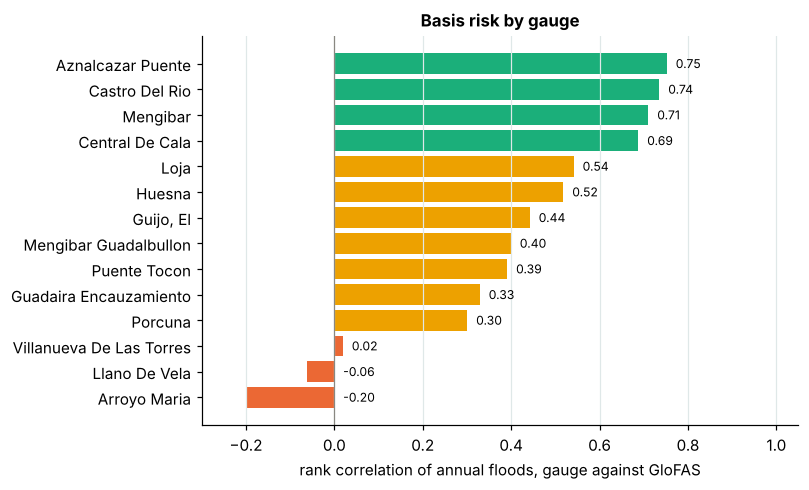

median rank correlation: 0.421


In [9]:
rho = pd.Series({gauges.loc[gid, "name"]: stats.spearmanr(am[am.gauge_id == gid].gauge_max_m3s, am[am.gauge_id == gid].glofas_max_m3s).statistic for gid in gauges.index}).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(rho.index, rho.values, color=[OK if r >= 0.6 else AMBER if r >= 0.3 else MODEL for r in rho.values])
for i, r in enumerate(rho.values): ax.text(max(r, 0) + 0.02, i, f"{r:.2f}", va="center", fontsize=8)
ax.grid(axis="y", visible=False); ax.axvline(0, color=GREY, lw=0.8); ax.set(xlim=(-0.3, 1.05), xlabel="rank correlation of annual floods, gauge against GloFAS", title="Basis risk by gauge")
fig.savefig("figures/gq_rank.png"); plt.show()
print("median rank correlation:", round(rho.median(), 3))

## Check against the KAI engine's published results

In [10]:
e = engine["summary"]
p5 = pooled[pooled.trigger == "1 in 5"].set_index("written as")
mine = {"return period": [int(p5.loc["return period", k]) for k in ("caught", "missed", "false_payouts")],
        "fixed m³/s": [int(p5.loc["fixed m³/s", k]) for k in ("caught", "missed", "false_payouts")]}
theirs = {"return period": [e["pooled_1in5_return_period_trigger"][k] for k in ("hits", "misses", "false_payouts")],
          "fixed m³/s": [e["pooled_1in5_absolute_value_trigger"][k] for k in ("hits", "misses", "false_payouts")]}
print("1-in-5 (caught, missed, false payouts) · this notebook:", mine, "· KAI engine:", theirs)
assert mine == theirs, "trigger scores drifted from the published results"
assert abs(ten["glofas ÷ gauge"].median() - e["median_ratio_glofas_to_observed"]["10"]) < 0.02
assert abs(rho.median() - e["median_rank_correlation"]) < 0.01
summary = {"gauges": len(gauges), "median_10yr_ratio": round(float(ten["glofas ÷ gauge"].median()), 3), "median_rank_correlation": round(float(rho.median()), 3),
           "pooled_1in5": {k: dict(zip(("caught", "missed", "false_payouts"), v)) for k, v in mine.items()}, "model": engine["data"]["model"]}
pathlib.Path("results/nb1_results.json").write_text(json.dumps(summary, indent=1)); print("checks passed:", summary)

1-in-5 (caught, missed, false payouts) · this notebook: {'return period': [30, 30, 27], 'fixed m³/s': [6, 54, 10]} · KAI engine: {'return period': [30, 30, 27], 'fixed m³/s': [6, 54, 10]}
checks passed: {'gauges': 14, 'median_10yr_ratio': 0.22, 'median_rank_correlation': 0.421, 'pooled_1in5': {'return period': {'caught': 30, 'missed': 30, 'false_payouts': 27}, 'fixed m³/s': {'caught': 6, 'missed': 54, 'false_payouts': 10}}, 'model': {'source': 'Open-Meteo Flood API', 'dataset': 'cems-glofas-historical', 'version': 'version_4_0', 'product': 'consolidated', 'window': ['1984-10-01', '2022-09-30']}}


## What it means

* **The global model runs low in this basin.** Its 10-year flood is about a fifth of the measured one at the median gauge. The Guadalquivir is dammed and irrigated; much of its flood water is managed in ways a global model cannot know. A wider search round the largest gauge found no bigger river cell, so this is the model, not the cell.
* **So never write a trigger in m³/s straight from the model.** At 1-in-5, the fixed-flow trigger caught 6 of 60 flood years; the same trigger written as the model's own return period caught 30.
* **Basis risk is still too high to sell on the model alone.** The return-period trigger paid 27 times in years without a flood, and at the median gauge the model ranks the big years only moderately well (0.42). A contract needs local calibration: a gauge, satellite flood maps or local flood records.
* **Limits.** One basin, strongly regulated; GloFAS 4.0; annual maxima of daily means (instantaneous peaks are higher); 17 to 24 years per gauge, so levels beyond 1-in-25 are extrapolations. The cell choice uses the gauge (best case).

**In KAI.** This is the test bench behind [KAI-Hydro's parametric flood triggers](https://kai-water.charkaks0.workers.dev/solution-parametric-triggers): pick a point on the map, get the flood history at the river cell, return levels with their bands, four ways to write the trigger, and its hits, misses and false payouts before the policy is written. Next: the same test on GloFAS 5.0 (1980 to today).

*References:* Hosking, J.R.M. and Wallis, J.R. (1997) *Regional Frequency Analysis*, Cambridge University Press · Harrigan, S. et al. (2020) GloFAS-ERA5 operational global river discharge reanalysis 1979–present, *Earth Syst. Sci. Data* 12, 2043–2060 · CEDEX, *Anuario de Aforos 2021-2022*.